# Data Loading and Library Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("CAR DETAILS FROM CAR DEKHO.csv")
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


# Data Inspection and MIssing Value Check

In [2]:
print(df.shape)
df.info()
print(df.isnull().sum())

(4340, 8)
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 515.2 KB
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


# Feature Engineering

In [3]:
df['brand'] = df['name'].apply(lambda x: str(x).split(' ')[0])
df['car_age'] = 2026 - df['year']
df[['name', 'brand', 'year', 'car_age', 'selling_price']].head()

,name,brand,year,car_age,selling_price
0,Maruti 800 AC,Maruti,2007,19,60000
1,Maruti Wagon R LXI Minor,Maruti,2007,19,135000
2,Hyundai Verna 1.6 SX,Hyundai,2012,14,600000
3,Datsun RediGO T Option,Datsun,2017,9,250000
4,Honda Amaze VX i-DTEC,Honda,2014,12,450000


# Exploratory Data Analysis

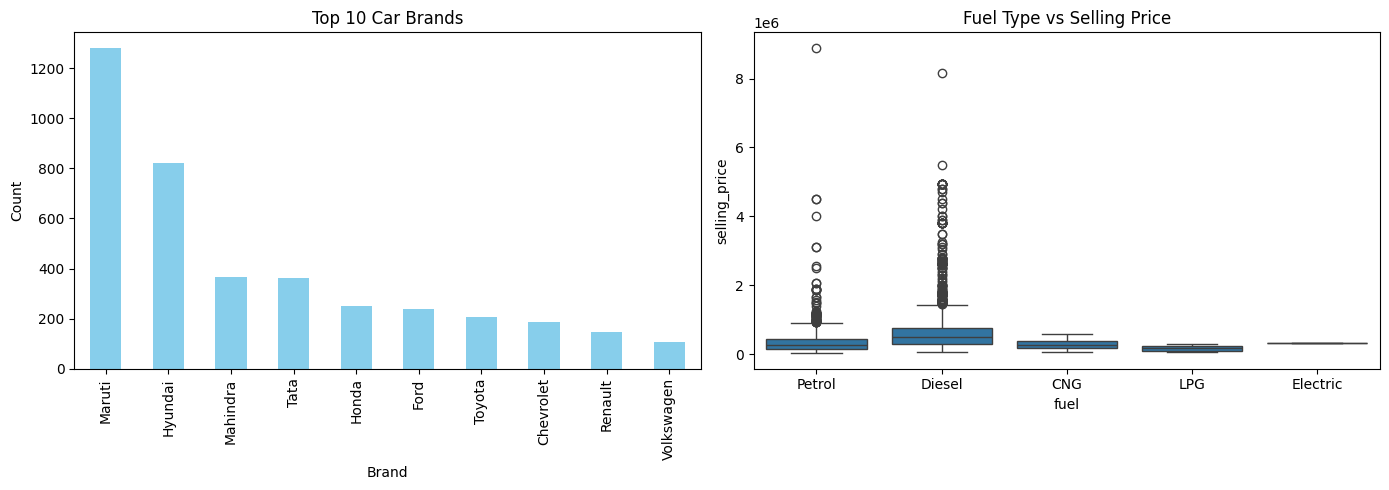

In [4]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
df['brand'].value_counts().head(10).plot(kind='bar', color='skyblue')
plt.title('Top 10 Car Brands')
plt.xlabel('Brand')
plt.ylabel('Count')

plt.subplot(1, 2, 2)
sns.boxplot(x='fuel', y='selling_price', data=df)
plt.title('Fuel Type vs Selling Price')

plt.tight_layout()
plt.show()

# Numerical Analysis(Price vs KM Driven and Car Age)

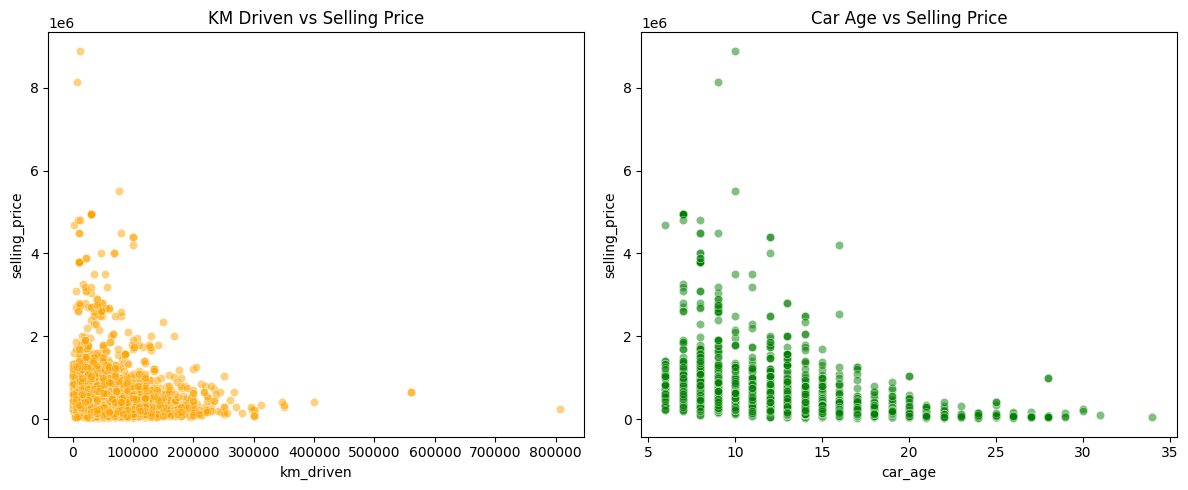

In [5]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(x='km_driven', y='selling_price', data=df, alpha=0.5, color='orange')
plt.title('KM Driven vs Selling Price')

plt.subplot(1, 2, 2)
sns.scatterplot(x='car_age', y='selling_price', data=df, alpha=0.5, color='green')
plt.title('Car Age vs Selling Price')

plt.tight_layout()
plt.show()

# Data Preprocessing and Train Test Split

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

features = ['brand', 'year', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']
X = df[features]
y = df['selling_price']

cat_cols = ['brand', 'fuel', 'seller_type', 'transmission', 'owner']
preprocessor = ColumnTransformer(
    transformers=[('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)],
    remainder='passthrough'
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(3472, 7) (868, 7)


# Machine Learning Model Training and Evaluation(Random Forest Regressor)

In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

model.fit(X_train, y_train)

score = r2_score(y_test, model.predict(X_test))
print("Model Accuracy:", score * 100)

Model Accuracy: 73.99467297612881


# Car Price Prediction on New Data

In [8]:
sample_car = pd.DataFrame([{
    'brand': 'Maruti',
    'year': 2018,
    'km_driven': 40000,
    'fuel': 'Petrol',
    'seller_type': 'Individual',
    'transmission': 'Manual',
    'owner': 'First Owner'
}])

pred_val = model.predict(sample_car)[0]
print("Predicted Price:", int(pred_val))

Predicted Price: 654122


# Building Streamlit Wb Application 

In [9]:
%%writefile app.py
import streamlit as st
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

st.set_page_config(page_title="Car Price Predictor", page_icon="🚗", layout="centered")

@st.cache_data
def load_data():
    data = pd.read_csv("CAR DETAILS FROM CAR DEKHO.csv")
    data['brand'] = data['name'].apply(lambda x: str(x).split(' ')[0])
    return data

df = load_data()

@st.cache_resource
def get_trained_model(data):
    features = ['brand', 'year', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']
    X = data[features]
    y = data['selling_price']

    cat_cols = ['brand', 'fuel', 'seller_type', 'transmission', 'owner']
    preprocessor = ColumnTransformer(
        transformers=[('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)],
        remainder='passthrough'
    )

    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
    ])
    pipe.fit(X, y)
    return pipe

model = get_trained_model(df)

st.title("🚗 Car Price Prediction App")
st.write("Enter car details below and click **Predict Price** to get the estimated market value of your car.")

col1, col2 = st.columns(2)

with col1:
    brand = st.selectbox("Brand", sorted(df['brand'].unique()))
    fuel = st.selectbox("Fuel Type", df['fuel'].unique())
    seller_type = st.selectbox("Seller Type", df['seller_type'].unique())
    year = st.number_input("Manufacturing Year", min_value=int(df['year'].min()), max_value=int(df['year'].max()), value=2017, step=1)

with col2:
    transmission = st.selectbox("Transmission", df['transmission'].unique())
    owner = st.selectbox("Owner Type", df['owner'].unique())
    km_driven = st.number_input("Kilometers Driven (km)", min_value=500, max_value=800000, value=45000, step=1000)

st.markdown("<br>", unsafe_allow_html=True)

if st.button("🔮 Predict Car Price", use_container_width=True):
    input_row = pd.DataFrame([{
        'brand': brand,
        'year': year,
        'km_driven': km_driven,
        'fuel': fuel,
        'seller_type': seller_type,
        'transmission': transmission,
        'owner': owner
    }])
    pred = model.predict(input_row)[0]
    st.success(f"### Estimated Selling Price: ₹ {int(pred):,}")

Writing app.py


In [ ]:
!streamlit run app.py

In [11]:
%%writefile requirements.txt
streamlit
pandas
numpy
scikit-learn

Writing requirements.txt
